### Business Objective: Predict whether a vision insurance claim is fraud-labeled using information available when the claim is submitted.

Prediction unit: One claim.

Target: is_fraud, where 1 means fraud-labeled and 0 means non-fraud-labeled.

Intended use: Prioritize claims for human review.

### Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from time import perf_counter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, 
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report)



### Load Dataset        

In [ ]:
DATA_PATH = Path("../dataset/VisionInsurance_claims_dataset.csv")

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["service_date", "submission_date"],
)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'dataset/VisionInsurance_claims_dataset.csv'

### Understand column types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38476 entries, 0 to 38475
Data columns (total 47 columns):
 #   Column                                       Non-Null Count  Dtype         
---  ------                                       --------------  -----         
 0   claim_id                                     38476 non-null  object        
 1   member_id                                    38476 non-null  object        
 2   provider_id                                  38476 non-null  object        
 3   service_date                                 38476 non-null  datetime64[ns]
 4   submission_date                              38476 non-null  datetime64[ns]
 5   fraud_type                                   38476 non-null  object        
 6   total_billed                                 38476 non-null  float64       
 7   log_total_billed                             38476 non-null  float64       
 8   max_line_billed                              38476 non-null  float64       


### Understand datatypes and missing values

In [ ]:
audit = pd.DataFrame({'dtype': df.dtypes.astype(str), 'nulls': df.isna().sum()})
display(audit)

,dtype,nulls
claim_id,object,0
member_id,object,0
provider_id,object,0
service_date,datetime64[ns],0
submission_date,datetime64[ns],0
fraud_type,object,0
total_billed,float64,0
log_total_billed,float64,0
max_line_billed,float64,0
billed_per_line,float64,0


### Lets inspect metadata columns, feature columns and target

In [ ]:
TARGET = "is_fraud"

METADATA_COLUMNS = [
    "claim_id",
    "member_id",
    "provider_id",
    "service_date",
    "submission_date",
    "fraud_type",
]

FEATURE_COLUMNS = [
    column
    for column in df.columns
    if column not in METADATA_COLUMNS + [TARGET]
]

assert len(FEATURE_COLUMNS) == 40
assert df[TARGET].notna().all()
assert set(df[TARGET].unique()) == {0, 1}
assert "fraud_type" not in FEATURE_COLUMNS

print(f"Candidate predictors: {len(FEATURE_COLUMNS)}")
print(f"Target: {TARGET}")

Candidate predictors: 40
Target: is_fraud


### Check basic data quality

In [ ]:
feature_inventory = pd.DataFrame({
    "dtype": df[FEATURE_COLUMNS].dtypes.astype(str),
    "unique_values": df[FEATURE_COLUMNS].nunique(),
    "missing_count": df[FEATURE_COLUMNS].isna().sum(),
    "missing_percent": df[FEATURE_COLUMNS].isna().mean() * 100,
})

display(
    feature_inventory
    .sort_values("missing_percent", ascending=False)
    .round(2)
)

### Inspect Categorical columns


In [ ]:
categorical_features = []
numeric_features = []
for column in FEATURE_COLUMNS:
    if(df[column].dtype == "object"):
        print(f"{column}: type:{df[column].dtype}: {df[column].unique()}\n")
        categorical_features.append(column)
    else :
        numeric_features.append(column)

print(f"Number of Categorical Features: {len(categorical_features)}")
print(f"Categorical Features:{categorical_features}")


primary_dx: type:object: ['H52.4' 'E11.9' 'H52.223' 'H52.03' 'Z01.00' 'H52.13' 'H25.9' 'H40.9']

secondary_dx: type:object: [nan 'H52.4' 'H52.13' 'H52.223' 'H52.03']

plan_type: type:object: ['Exam + materials' 'Exam only']

Number of Categorical Features: 3
Categorical Features:['primary_dx', 'secondary_dx', 'plan_type']


### Inspect Numeric columns

In [ ]:
for column in numeric_features:
    print(f"{column}: type:{df[column].dtype}: {df[column].unique()}\n")

print(f"Number of Numeric Features: {len(numeric_features)}")
print(f"Numeric Features: {numeric_features}")


total_billed: type:float64: [925.46 185.49 161.11 ... 186.61 281.73 638.09]

log_total_billed: type:float64: [6.83137087 5.22837762 5.08827512 ... 5.23436534 5.64449238 6.46004529]

max_line_billed: type:float64: [394.69 185.49 126.   ... 267.57 916.38  92.25]

billed_per_line: type:float64: [231.365      185.49        80.555      ... 130.77        71.02333333
 127.618     ]

line_count: type:int64: [4 1 2 3 5 6 7 8]

total_units: type:int64: [ 5  1  2  4  7  6 10  9  8 11  3 12]

claim_frequency_code: type:int64: [1 7]

frame_allowance: type:int64: [130 150 200]

age: type:int64: [47 17 49 51 44 46 27 63 42 41 34 86 59 52 76 21 54  4 65 92 72 24 57 69
 68 26 38 22 77 58 84  2 36 43 67 62 32 23 18 79 56 25 45 28 74 71 70 50
 39 78  8 14 31 61 60 40 75 20 11 15 48 81 16 55 19 83 35 29  7 53 73 64
 37 12 87 82 88 66 13 30 85 80 33  9 10 89  6  5 91  3 90]

has_chronic_condition: type:int64: [0 1]

submission_lag_days: type:int64: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 16 17 15 19 

### Summarize numeric measurements

In [ ]:

numeric_summary = df[numeric_features].describe()
display(numeric_summary.round(2))

,total_billed,log_total_billed,max_line_billed,billed_per_line,line_count,total_units,claim_frequency_code,frame_allowance,age,has_chronic_condition,...,provider_prior_mean_billed,billed_vs_provider_prior_mean,provider_prior_comprehensive_share,provider_prior_imaging_share,member_prior_claim_count,member_prior_claims_30d,member_prior_distinct_providers,member_provider_prior_claim_count,days_since_prior_routine_exam,prior_exact_duplicate_within_3_service_days
count,38476.00,38476.00,38476.00,38476.00,38476.00,38476.00,38476.00,38476.00,38476.00,38476.00,...,38064.00,38064.00,38064.00,38064.00,38476.00,38476.00,38476.00,38476.00,14761.00,38476.00
mean,348.93,5.63,188.65,130.64,2.61,3.56,1.06,152.05,46.46,0.39,...,371.40,0.96,0.42,0.17,0.84,0.08,0.51,0.70,259.99,0.00
std,263.26,0.67,105.29,59.52,1.31,2.60,0.60,25.65,20.35,0.49,...,123.48,0.67,0.25,0.10,1.23,0.30,0.60,1.12,175.73,0.06
min,55.10,4.03,55.10,47.25,1.00,1.00,1.00,130.00,2.00,0.00,...,84.68,0.05,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,163.99,5.11,119.25,92.91,2.00,2.00,1.00,130.00,33.00,0.00,...,284.60,0.47,0.14,0.12,0.00,0.00,0.00,0.00,111.00,0.00
50%,257.92,5.56,161.22,118.34,2.00,2.00,1.00,150.00,47.00,0.00,...,349.55,0.69,0.53,0.16,0.00,0.00,0.00,0.00,250.00,0.00
75%,475.41,6.17,229.41,152.67,4.00,5.00,1.00,150.00,61.00,1.00,...,431.94,1.36,0.60,0.21,1.00,0.00,1.00,1.00,387.00,0.00
max,3613.32,8.19,1479.14,997.76,8.00,12.00,7.00,200.00,92.00,1.00,...,2772.58,8.56,1.00,1.00,10.00,6.00,4.00,10.00,727.00,1.00


 ### Understand class imbalance

,claim_count,percentage
is_fraud,,
0,37322,97.0
1,1154,3.0


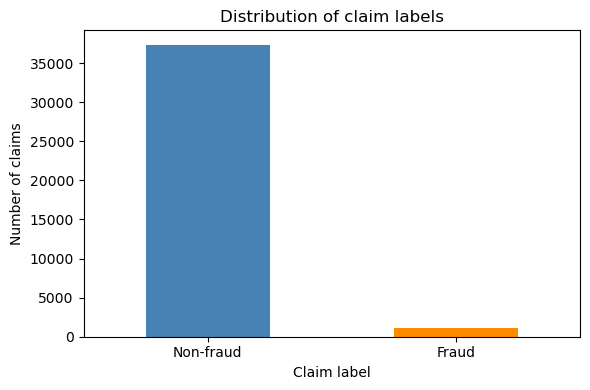

In [ ]:
class_summary = (
    df[TARGET]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("is_fraud")
    .to_frame("claim_count")
)

class_summary["percentage"] = (
    class_summary["claim_count"] / len(df) * 100
)

display(class_summary.round(2))

ax = class_summary["claim_count"].plot(
    kind="bar",
    color=["steelblue", "darkorange"],
    figsize=(6, 4),
)

ax.set_xticklabels(["Non-fraud", "Fraud"], rotation=0)
ax.set_title("Distribution of claim labels")
ax.set_xlabel("Claim label")
ax.set_ylabel("Number of claims")

plt.tight_layout()
plt.show()

### Observation
Approximately 3% of claims are fraud-labeled. A model predicting every claim as non-fraud would achieve approximately 97% accuracy but detect no fraud. We therefore need precision, recall, and average precision to evaluate model usefulness.

### Examine categorical frequencies and fraud rates

In [ ]:
def category_summary(data, column):
    values = (
        data[column]
        .astype("string")
        .fillna("Not supplied")
    )

    summary = (
        data.assign(category=values)
        .groupby("category")[TARGET]
        .agg(claims="size", fraud_claims="sum", fraud_rate="mean")
    )

    summary["fraud_percent"] = summary.pop("fraud_rate") * 100

    return summary.sort_values("claims", ascending=False)

for column in categorical_features:
    print(f"\n{column}")
    display(category_summary(df, column).round(2))


primary_dx


,claims,fraud_claims,fraud_percent
category,,,
Z01.00,11911,522,4.38
E11.9,6281,30,0.48
H52.4,5535,168,3.04
H52.223,4204,153,3.64
H52.03,4185,153,3.66
H52.13,4140,119,2.87
H25.9,1141,5,0.44
H40.9,1079,4,0.37



secondary_dx


,claims,fraud_claims,fraud_percent
category,,,
Not supplied,26565,632,2.38
H52.4,3652,184,5.04
H52.13,2791,112,4.01
H52.223,2743,127,4.63
H52.03,2725,99,3.63



plan_type


,claims,fraud_claims,fraud_percent
category,,,
Exam + materials,31042,937,3.02
Exam only,7434,217,2.92



claim_frequency_code


,claims,fraud_claims,fraud_percent
category,,,
1,38091,998,2.62
7,385,156,40.52


### Compare billing distributions

We’ll compare raw billing with its existing log transformation.

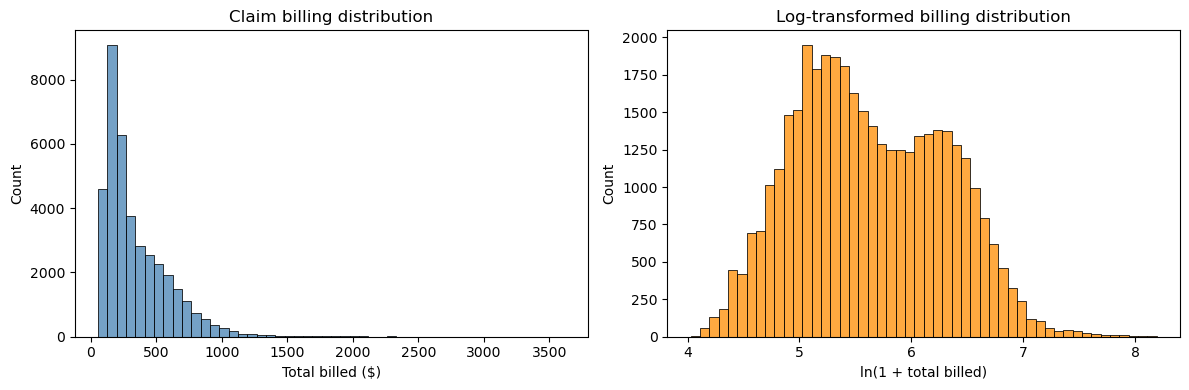

Raw billing skewness: 2.40
Log billing skewness: 0.23


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=df,
    x="total_billed",
    bins=50,
    ax=axes[0],
    color="steelblue",
)
axes[0].set_title("Claim billing distribution")
axes[0].set_xlabel("Total billed ($)")

sns.histplot(
    data=df,
    x="log_total_billed",
    bins=50,
    ax=axes[1],
    color="darkorange",
)
axes[1].set_title("Log-transformed billing distribution")
axes[1].set_xlabel("ln(1 + total billed)")

plt.tight_layout()
plt.show()

print(f"Raw billing skewness: {df['total_billed'].skew():.2f}")
print(f"Log billing skewness: {df['log_total_billed'].skew():.2f}")

### Compare billing between fraud and non-fraud

Normalize the distributions separately so the much larger non-fraud class does not overwhelm the plot.

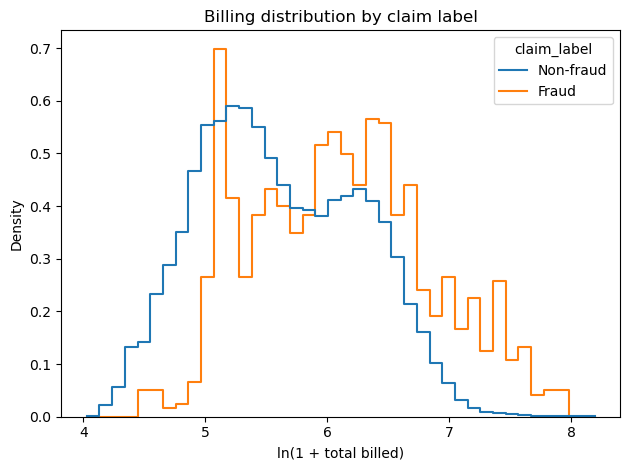

,count,median,mean
is_fraud,,,
0,37322,254.08,341.30
1,1154,444.80,595.52


In [ ]:
plot_data = df.assign(
    claim_label=df[TARGET].map({
        0: "Non-fraud",
        1: "Fraud",
    })
)

sns.histplot(
    data=plot_data,
    x="log_total_billed",
    hue="claim_label",
    hue_order=["Non-fraud", "Fraud"],
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)

plt.title("Billing distribution by claim label")
plt.xlabel("ln(1 + total billed)")
plt.tight_layout()
plt.show()

display(
    df.groupby(TARGET)["total_billed"]
    .agg(["count", "median", "mean"])
    .round(2)
)

Observation: A difference between the distributions suggests billing could help distinguish the classes. Any overlap means billing alone cannot reliably separate them. Each curve is normalized independently; its height does not represent the total number of claims.

### Compare several numeric features

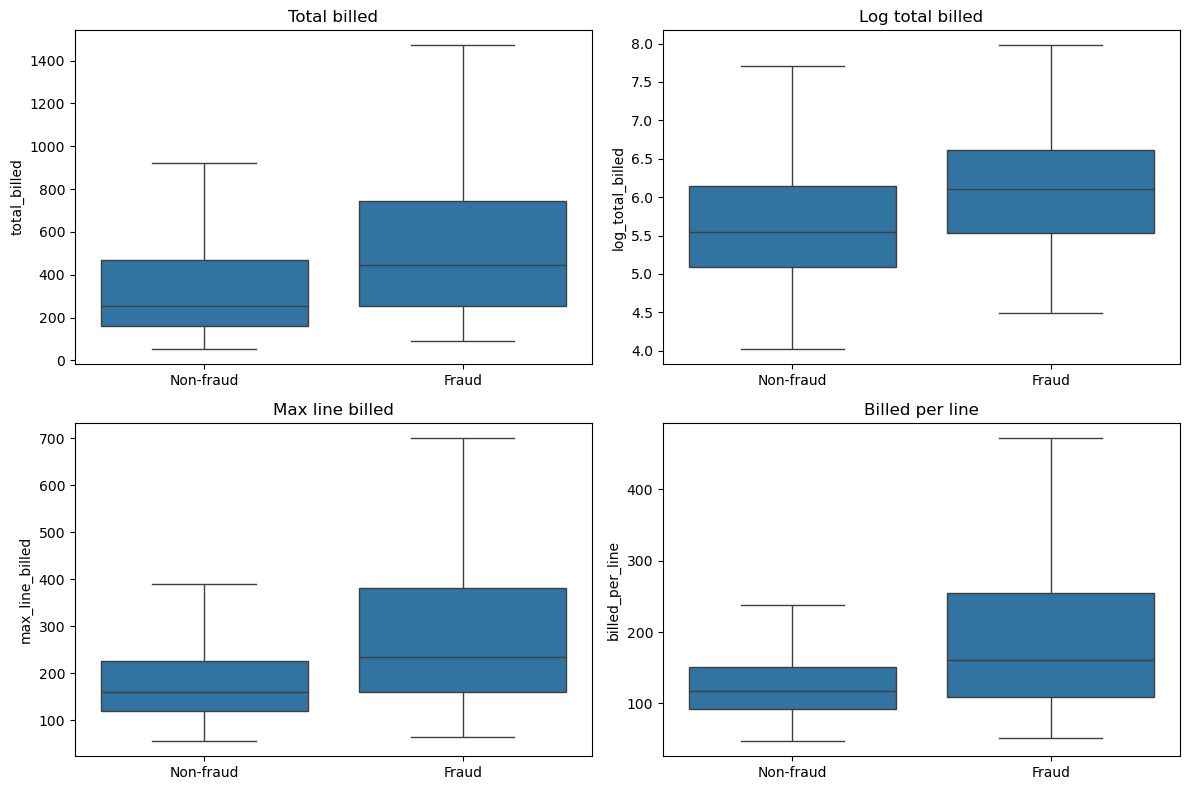

is_fraud,Non-fraud median,Fraud median
total_billed,254.08,444.80
log_total_billed,5.54,6.10
max_line_billed,159.62,233.36
billed_per_line,117.67,160.41
line_count,2.00,3.00
total_units,2.00,3.00
claim_frequency_code,1.00,1.00
frame_allowance,150.00,150.00
age,47.00,46.00
has_chronic_condition,0.00,0.00


In [ ]:
#comparison_features = [    "total_billed",    "billed_vs_provider_prior_mean",    "submission_lag_days",    "member_prior_claims_30d",]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, numeric_features):
    sns.boxplot(
        data=plot_data,
        x="claim_label",
        y=feature,
        order=["Non-fraud", "Fraud"],
        showfliers=False,
        ax=ax,
    )
    ax.set_title(feature.replace("_", " ").capitalize())
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

display(
    df.groupby(TARGET)[numeric_features]
    .median()
    .T
    .rename(columns={0: "Non-fraud median", 1: "Fraud median"})
    .round(2)
)

### Investigate rule-based flags

,feature,flagged_claims,fraud_claims,fraud_percent
2,s_code_with_refraction,30,30,100.00
1,prior_exact_duplicate_within_3_service_days,151,143,94.70
3,fitting_without_contacts,108,82,75.93
5,materials_without_exam,238,95,39.92
0,outside_coverage,157,57,36.31
4,imaging_with_routine_primary_dx,770,217,28.18


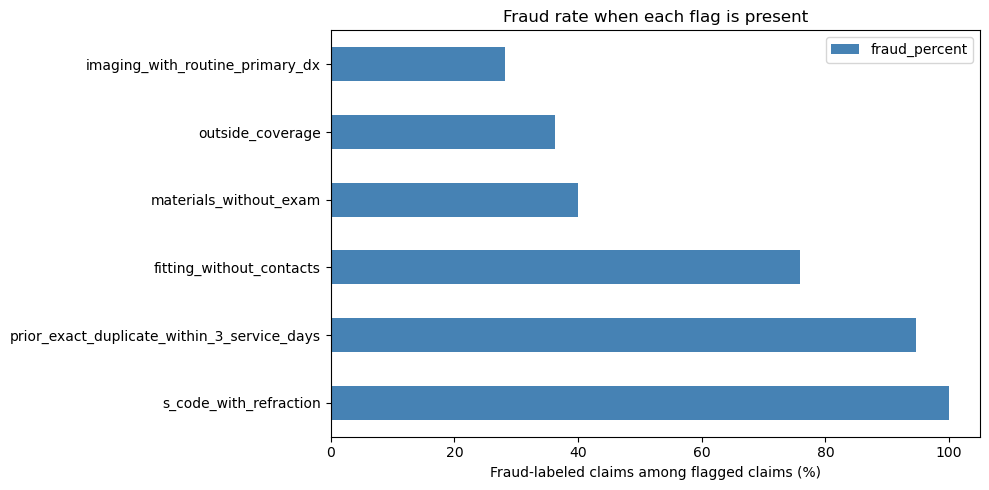

In [ ]:
flag_features = [
    "outside_coverage",
    "prior_exact_duplicate_within_3_service_days",
    "s_code_with_refraction",
    "fitting_without_contacts",
    "imaging_with_routine_primary_dx",
    "materials_without_exam",
]

flag_rows = []

for feature in flag_features:
    flagged = df.loc[df[feature].eq(1), TARGET]

    flag_rows.append({
        "feature": feature,
        "flagged_claims": len(flagged),
        "fraud_claims": int(flagged.sum()),
        "fraud_percent": flagged.mean() * 100,
    })

flag_summary = (
    pd.DataFrame(flag_rows)
    .sort_values("fraud_percent", ascending=False)
)

display(flag_summary.round(2))

ax = flag_summary.set_index("feature")["fraud_percent"].plot.barh(
    figsize=(10, 5),
    color="steelblue",
)



ax.set_xlabel("Fraud-labeled claims among flagged claims (%)")
ax.set_ylabel("")
ax.set_title("Fraud rate when each flag is present")
ax.legend()

plt.tight_layout()
plt.show()

### Examine correlated predictors

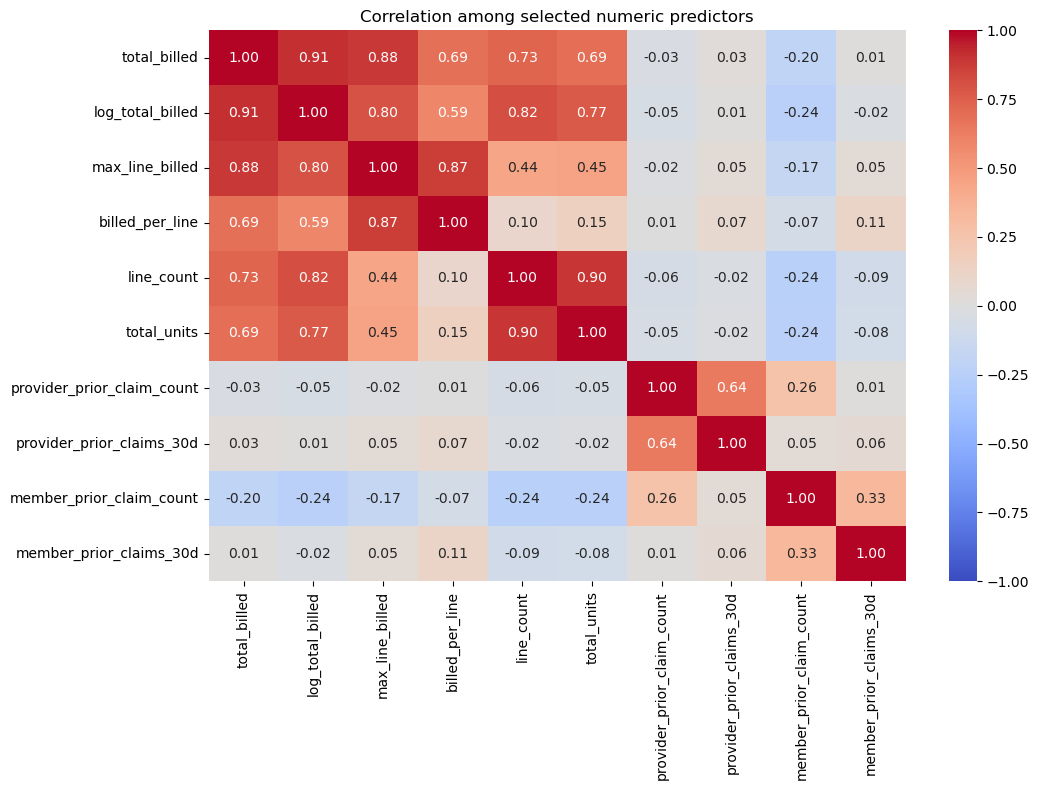

In [ ]:
correlation_features = [
    "total_billed",
    "log_total_billed",
    "max_line_billed",
    "billed_per_line",
    "line_count",
    "total_units",
    "provider_prior_claim_count",
    "provider_prior_claims_30d",
    "member_prior_claim_count",
    "member_prior_claims_30d",
]

correlations = df[correlation_features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Correlation among selected numeric predictors")
plt.tight_layout()
plt.show()

Interpretation: Strong correlations indicate overlapping information. 

### Check whether missing history is informative

In [ ]:
history_features = [
    "provider_prior_mean_billed",
    "days_since_prior_routine_exam",
]

for feature in history_features:
    summary = (
        df.assign(history_missing=df[feature].isna())
        .groupby("history_missing")[TARGET]
        .agg(claims="size", fraud_claims="sum", fraud_rate="mean")
    )

    summary["fraud_percent"] = summary.pop("fraud_rate") * 100

    print(f"\n{feature}")
    display(summary.round(2))


provider_prior_mean_billed


,claims,fraud_claims,fraud_percent
history_missing,,,
False,38064,1142,3.00
True,412,12,2.91



days_since_prior_routine_exam


,claims,fraud_claims,fraud_percent
history_missing,,,
False,14761,560,3.79
True,23715,594,2.50
